In [1]:
#!/usr/bin/env python                                                                       
'''
2026-10-20

Check online tracer diagnostics (including MLD diags)

[tracers are now volume integrated - unit should be "tracer unit m-3 second-1"]

'''                                                                                         
######################
#import useful modules
######################

import os,sys

####################

#sys.path.append("/data-gigatl/data/Python_Modules_p3/") 
MODULE_PATH = os.environ.get("CROCO_MODULE_PATH", "/home/gula/Desktop/Work_capella/Python/Python_Modules_p3/")
sys.path.append(MODULE_PATH) 

from Modules import *
from Modules_gula import *

####################

import numpy.ma as ma

os.makedirs('./Figures', exist_ok=True)

#plotting functions
%matplotlib inline


no amg module


In [2]:
###################################################################################
# Load simulations parameters (date, subsection, static fields, files path ...etc..)
# [you can check "dir(simul)" to see what has been loaded]
###################################################################################

#mysimul = 'porcupt'; 
mysimul = 'gulfstream_diagnostics_tracer_2026'; 


#######################################
# Time settings
#######################################

time_avg = 1
navg = 10

time_his = time_avg * navg + 1
time_his_0 = time_avg * navg
time_his_1 = (time_avg + 1) * navg

#######################################

simul_his = load(mysimul, time=time_his, output=False)
simul_ts = load(mysimul + '_ts', time=time_his-1, output=False)
#simul_ts.mask = simul_ts.mask / (simul_ts.pn*simul_ts.pm)

###########################################################################

print(simul_his.oceantime)
print(simul_ts.oceantime)


23760
23760


In [4]:

vertint = True # Do I want vertically integrated results
croco_vertint = True # are the diags already vertically integrated

###########################################################################

#simul_his = load(mysimul,time = time_his , output=False)

def get_Hz(simul_his, iz=None):
    [z_r, z_w] = tools.get_depths(simul_his)
    Hz = z_w[:,:,1:] - z_w[:,:,:-1]
    return Hz

def get_hbl_mask(simul_his, iz=None, eps=1e-10):
    [z_r, z_w] = tools.get_depths(simul_his)
    if iz is None:
        hbls = var('hbl',simul_his).data
        Hz = np.ones_like(z_r) #z_w[:,:,1:] - z_w[:,:,:-1]
        Hz[z_r<z_w[:,:,-1,None]-hbls[:,:,None]+eps] = 0.  # +eps: include cells exactly at the MLD boundary
    else:
        if iz<0: iz+=z_r.shape[2]
        Hz = np.zeros_like(z_r) #z_w[:,:,1:] - z_w[:,:,:-1]
        Hz[:,:,iz]= 1.
    return Hz

def get_Hz_hbl(simul_his, iz=None, eps=1e-10):
    [z_r, z_w] = tools.get_depths(simul_his)
    if iz is None:
        hbls = var('hbl',simul_his).data
        Hz = z_w[:,:,1:] - z_w[:,:,:-1]
        #Hz[z_r<z_w[:,:,-1,None]-hbls[:,:,None]-eps] = 0.
        Hz[z_w[:,:,:-1]<z_w[:,:,-1,None]-hbls[:,:,None]-eps] = 0.  # -eps: exclude boundary cell from thickness integration    
    else:
        if iz<0: iz+=z_r.shape[2]
        Hz = np.zeros_like(z_r)
        Hz[:,:,iz]= z_w[:,:,iz+1] - z_w[:,:,iz]
    return Hz

# Hz used for vertical integration
if croco_vertint:
    Hz = None
else:
    Hz = get_Hz(simul_his)
    
Hz_hbl = get_Hz_hbl(simul_his)
Hz_hbl_mask = get_hbl_mask(simul_his)

##################################

def vert(myvar, Hz=None, iz=-1, vertint=True):
    # Hz=None is correct for pre-integrated diagnostics (croco_vertint=True):
    if vertint:
        if Hz is None:
            out = np.nansum(myvar,axis=2)
        else:
            out = np.nansum(Hz * myvar,axis=2)
    else:
        out = myvar[:,:,iz]
    return out

##################################



## Some basic plotting functions

In [9]:
###########################################################################

fontsize0 = 6
fontsize1 = 10
fontsize2 = 14
fontsize3 = 18
font = {'size'   : fontsize1}
py.rc('font', **font)


def plot_common(simul,ax1,myvar,title,panel,levels):
    my_cmap= plot.ncview_colormap('blue_red')
    joe = py.pcolormesh(simul.x.T,simul.y.T,ma.masked_invalid(myvar.T),\
                        vmin=levels.min(),vmax=levels.max(),cmap=my_cmap,rasterized=True,shading='auto');
    py.contour( simul.x.T,simul.y.T, simul.topo.T,[1,100,500,1000],colors = ('k',),linewidths = (0.1,))
    #py.axis('scaled');  #py.axis(zoom)
    t1 = py.text(0.9, 0.21,"{0:.2f}".format(np.nansum(myvar[1:-1,1:-1])), fontsize=fontsize0,\
                 horizontalalignment='right', verticalalignment='center', transform = ax1.transAxes)
    t1 = py.text(0.9, 0.11,title, fontsize=fontsize1, \
                 horizontalalignment='right', verticalalignment='center', transform = ax1.transAxes)
    color = 'w'; box = 'circle,pad=0.15'; props = dict(boxstyle=box, fc=color, ec='k', lw=1, alpha=0.5)
    if panel!=' ': ax1.text(0.1,0.9,panel, fontsize=fontsize2, \
                            horizontalalignment='left', verticalalignment='top', bbox=props, transform=ax1.transAxes)
    #xmajorLocator   = MultipleLocator(0.5)
    #ax1.xaxis.set_major_locator(xmajorLocator)
    #ax1.yaxis.set_major_locator(xmajorLocator)
    ax1.xaxis.set_major_formatter( NullFormatter() )
    ax1.yaxis.set_major_formatter( NullFormatter() )
    return joe



def panels9(simul,var1,var2,var3,var4,var5,var6,var7,var8,var9,filename,titles=[' ']*10,title=' ', coeflev=1.):
    fig = py.figure(figsize=(8.0,6.0))
    levels = np.arange(-1,1.01,0.01) #*coeflev
    ############################################################
    ax1 = fig.add_subplot(331,facecolor='Gainsboro')
    joe = plot_common(simul,ax1,var1/coeflev,titles[0],'a',levels)
    ############################################################
    ax1 = fig.add_subplot(332,facecolor='Gainsboro')
    plot_common(simul,ax1,var2/coeflev,titles[1],'b',levels)
    ############################################################
    ax1 = fig.add_subplot(333,facecolor='Gainsboro')
    plot_common(simul,ax1,var3/coeflev,titles[2],'c',levels)
    ############################################################
    ax1 = fig.add_subplot(334,facecolor='Gainsboro')
    plot_common(simul,ax1,var4/coeflev,titles[3],'d',levels)
    ############################################################
    ax1 = fig.add_subplot(335,facecolor='Gainsboro')
    plot_common(simul,ax1,var5/coeflev,titles[4],'e',levels)
    ############################################################
    ax1 = fig.add_subplot(336,facecolor='Gainsboro')
    plot_common(simul,ax1,var6/coeflev,titles[5],'f',levels)
    ############################################################
    ax1 = fig.add_subplot(337,facecolor='Gainsboro')
    plot_common(simul,ax1,var7/coeflev,titles[6],'g',levels)
    ############################################################
    ax1 = fig.add_subplot(338,facecolor='Gainsboro')
    plot_common(simul,ax1,var8/coeflev,titles[7],'h',levels)
    ############################################################
    ax1 = fig.add_subplot(339,facecolor='Gainsboro')
    plot_common(simul,ax1,var9/coeflev,titles[8],'i',levels)    
    ############################################################
    py.subplots_adjust(right=0.9)
    py.subplots_adjust(wspace=0.01,hspace=0.01)
    cbar_ax = fig.add_axes([0.94, 0.32, 0.02, 0.30])
    fig.colorbar(joe, cax=cbar_ax,ticks=oldsim.clabels(levels))
    py.suptitle(title)
    ############################################################
    py.savefig('./Figures/'+filename + '.png', dpi=200,bbox_inches='tight')
    #py.clf()
    ############################################################

###################################################################################


def panels4(simul, var1, var2, var3, var4, filename, titles=[' ', ' ', ' ', ' '], coeflev=1.):
    """
    Create a figure with four panels.

    Parameters:
    - simul: Simulation object.
    - var1, var2, var3, var4: Variables to plot.
    - filename: Name of the file to save the figure.
    - titles: List of titles for each panel.
    - coeflev: Coefficient for levels.
    """
    fig = plt.figure(figsize=(8.0, 6.0))
    levels = np.arange(-1, 1.01, 0.01)

    ax1 = fig.add_subplot(221, facecolor='Gainsboro')
    joe = plot_common(simul, ax1, var1 / coeflev, titles[0], 'a', levels)

    ax1 = fig.add_subplot(222, facecolor='Gainsboro')
    plot_common(simul, ax1, var2 / coeflev, titles[1], 'b', levels)

    ax1 = fig.add_subplot(223, facecolor='Gainsboro')
    plot_common(simul, ax1, var3 / coeflev, titles[2], 'c', levels)

    ax1 = fig.add_subplot(224, facecolor='Gainsboro')
    plot_common(simul, ax1, var4 / coeflev, titles[3], 'd', levels)

    plt.subplots_adjust(right=0.9, wspace=0.01, hspace=0.01)
    cbar_ax = fig.add_axes([0.94, 0.32, 0.02, 0.30])
    fig.colorbar(joe, cax=cbar_ax, ticks=oldsim.clabels(levels))
    plt.savefig('./Figures/' + filename + '.png', dpi=200, bbox_inches='tight')

  
    
###################################################################################

def panels2(simul, var1, var2, filename, titles=[' ', ' ', ' ', ' '], coeflev=1.):
    """
    Create a figure with two panels.

    Parameters:
    - simul: Simulation object.
    - var1, var2: Variables to plot.
    - filename: Name of the file to save the figure.
    - titles: List of titles for each panel.
    - coeflev: Coefficient for levels.
    """
    fig = plt.figure(figsize=(8.0, 3.0))
    levels = np.arange(-1, 1.01, 0.01)

    ax1 = fig.add_subplot(121, facecolor='Gainsboro')
    joe = plot_common(simul, ax1, var1 / coeflev, titles[0], 'a', levels)

    ax1 = fig.add_subplot(122, facecolor='Gainsboro')
    plot_common(simul, ax1, var2 / coeflev, titles[1], 'b', levels)

    plt.subplots_adjust(right=0.9, wspace=0.01, hspace=0.01)
    cbar_ax = fig.add_axes([0.94, 0.32, 0.02, 0.30])
    fig.colorbar(joe, cax=cbar_ax, ticks=oldsim.clabels(levels))
    plt.savefig('./Figures/'+ filename + '.png', dpi=200, bbox_inches='tight')



## Vertically integrated tracer budget terms


- Check that the pointwise tracer budget is closed (based on terms defined in the NetCDF file):

```
C_rate = C_xadv + C_yadv + C_vadv + C_vmix + C_hmix + C_forc 
```


**The important is that the difference```C_rate - C_tot``` (where ```C_tot``` is the sum of all the r.h.s. terms) remains very small. See the bottom right panel in the following figures.**

The result should be close to zero up to rounding errors (about 1e-9 with single precision, 1e-13 with double precision — with `#define OUT_DOUBLE`).


diags_ts_gulfstream_diagnostics_tracer_2026_ts
######################################
tsrate is  -1109283027.4645116
tstot - tsrate is  -0.00012017864493429897
error is 1.0833902796565031e-13
######################################


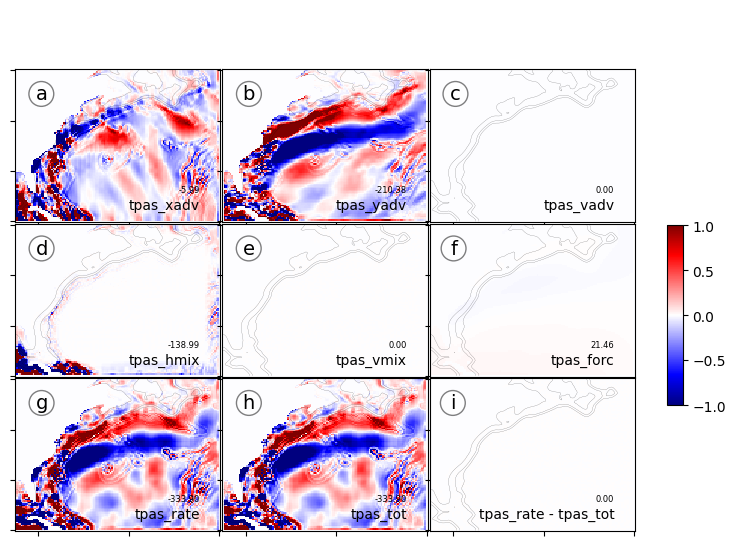

In [11]:
tracer = 'temp' # choose 'temp', 'salt', 'tpas01', etc.

print('diags_ts_' + simul_ts.simul)

ts_rate = vert(var(tracer+'_rate',simul_ts).data,Hz)*simul_ts.mask
ts_xadv = vert(var(tracer+'_xadv',simul_ts).data,Hz)*simul_ts.mask
ts_yadv = vert(var(tracer+'_yadv',simul_ts).data,Hz)*simul_ts.mask
ts_vadv = vert(var(tracer+'_vadv',simul_ts).data,Hz)*simul_ts.mask
ts_hmix = vert(var(tracer+'_hmix',simul_ts).data,Hz)*simul_ts.mask
ts_vmix = vert(var(tracer+'_vmix',simul_ts).data,Hz)*simul_ts.mask
ts_forc = vert(var(tracer+'_forc',simul_ts).data,Hz)*simul_ts.mask

# sum
ts_tot = ts_xadv + ts_yadv + ts_vadv + ts_hmix + ts_vmix + ts_forc

print('######################################')
print('tsrate is ', np.nansum(ts_rate))
print('tstot - tsrate is ', np.nansum(ts_tot - ts_rate))
print('error is', np.abs(np.nansum(ts_tot - ts_rate)/np.nansum(ts_rate)))
print('######################################')

titles = ['tpas_xadv', 'tpas_yadv', 'tpas_vadv', 'tpas_hmix', 'tpas_vmix',\
          'tpas_forc',  'tpas_rate', 'tpas_tot','tpas_rate - tpas_tot']

coeflev = np.nanmax(np.abs(ts_rate))*0.1

panels9(simul_ts,ts_xadv,\
                 ts_yadv,\
                 ts_vadv,\
                 ts_hmix,\
                 ts_vmix,\
                 ts_forc,\
                 ts_rate,\
                 ts_tot,\
                 ts_rate - ts_tot,'check_tsvert_' + simul_ts.simul,
                 coeflev=coeflev, titles= titles)

###################################################################################


## Tracer evolution

- Check that the pointwise tracer budget terms ($\Delta C_{j}^{n+\frac{1}{2}}$) capture the time evolution of the tracer between time steps $n$ and $n+1$.

$$\frac{H^{n+1} C^{n+1} - H^{n} C^n}{\Delta t} =  \sum_j \, \Delta C_{j}^{n+\frac{1}{2}}$$

The l.h.s is computed by using two consecutive history files, the r.h.s. by using momentum budget terms averaged over the same period.

**The important is to check that the difference ```C_rate - dCdt``` remains very small. See the bottom panels in the following figures.**


 
check that the following scrum times are the same: 
history:  32580
tracer budget:  32580
average:  32580
21600


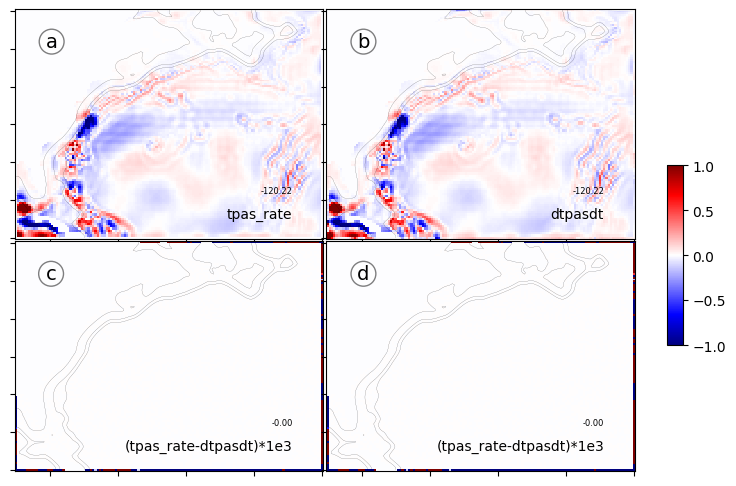

In [12]:
###########################################################################

simul_ts = load(mysimul + '_ts_avg', time = time_avg, output = False)
simul_avg = load(mysimul + '_avg', time = time_avg, output = False)
simul_his_0 = load(mysimul + '_his', time = time_his_0, output = False)
simul_his_1 = load(mysimul + '_his', time = time_his_1, output = False)

###########################################################################

print(' ')
print('check that the following scrum times are the same:', end=' \n') 
print('history: ',(simul_his_0.oceantime + simul_his_1.oceantime + int(simul_his_0.dt_model))//2)
print('tracer budget: ',simul_ts.oceantime )
print('average: ',simul_avg.oceantime )

print(simul_his_1.oceantime - simul_his_0.oceantime)
###########################################################################


# check with all data

Hz_0 = get_Hz(simul_his_0); 
Hz_1 = get_Hz(simul_his_1)

tpas0 = vert(var(tracer,simul_his_0).data,Hz_0)\
        * simul_his_0.mask / simul_his_0.pm / simul_his_0.pn
tpas1 = vert(var(tracer,simul_his_1).data,Hz_1)\
        * simul_his_1.mask / simul_his_1.pm / simul_his_1.pn

dtsdt = ( tpas1 - tpas0 ) / simul_avg.dt

ts_rate = vert(var(tracer+'_rate',simul_ts).data,Hz)*simul_ts.mask

if not croco_vertint:
    ts_rate = ts_rate/ simul_his_0.pm / simul_his_0.pn

titles = ['tpas_rate', 'dtpasdt','(tpas_rate-dtpasdt)*1e3','(tpas_rate-dtpasdt)*1e3']

panels4(simul_avg,ts_rate,\
                  dtsdt,\
                  (ts_rate-dtsdt)*1e3,\
                  (ts_rate-dtsdt)*1e3,\
        'check_tsrate_' + simul_avg.simul,\
        titles= titles, coeflev=1e7)



### Note on hbl computation (offline versus online)

Offline computation (based on T/S fields) is the same than the online one if you include a computation of mld at the predictor step (just before saving outputs) otherwise there is always a difference because in the code you use hbls computed at the corrector time-step - but before updating tracers.

Below we are just checking that the sum of Hz gives the same than the actual hbl, asuming that the definition is based on z_w:

`Tcrit_mld(i,j,itrc)= z_w(i,j,N)-z_w(i,j,kbl1(i,j)-1)`

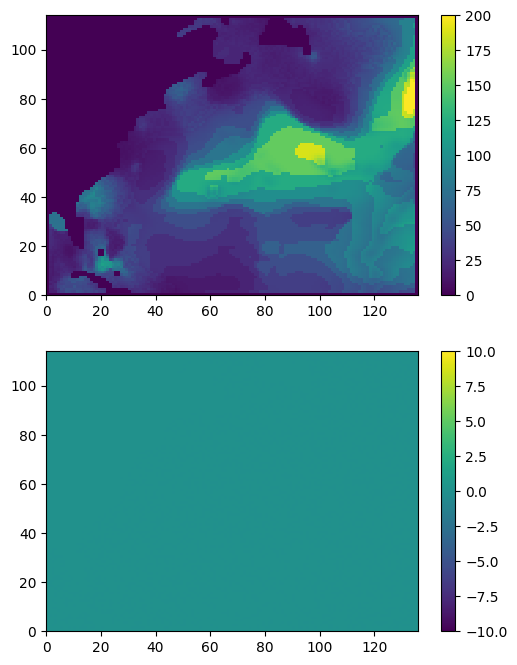

In [13]:


# hbl in file
hbls = var('hbl',simul_his).data

# compute hbl offline from rho
#hbls_rho = var('hbls_rho',simul_his).data

hbls_off = np.nansum(Hz_hbl, axis=-1)


###################################################################################

fig = py.figure(figsize=(6.0,8.0))
#################
ax1 = fig.add_subplot(211,facecolor='Gainsboro')
plt.pcolormesh(hbls.T , vmin=0,vmax=200); plt.colorbar()

ax1 = fig.add_subplot(212,facecolor='Gainsboro')
plt.pcolormesh((hbls_off-hbls).T , vmin=-10,vmax=10); plt.colorbar()


## Plot MLD integrated tracer budget terms

- Check that the pointwise MLD tracer budget is closed (based on terms defined in the NetCDF file):

```
C_rate_mld = C_xadv_mld + C_yadv_mld + C_vadv_mld + C_vmix_mld + C_hmix_mld + C_forc_mld + C_entr_mld
```

The main difference with the 3d budget is the addition of the entrainment term: ```C_entr_mld```, which includes changes due to the mld changes and is computed by residual

**The important is that the difference```C_rate_mld - C_tot_mld``` (where ```C_tot_mld``` is the sum of all the r.h.s. terms) remains very small. See the bottom right panel in the following figures.**


diags_ts_gulfstream_diagnostics_tracer_2026_ts
######################################
tsrate is  28322662963.474937
tstot - tsrate is  1.472836725469051e-06
error is 5.2002056705205634e-17
######################################


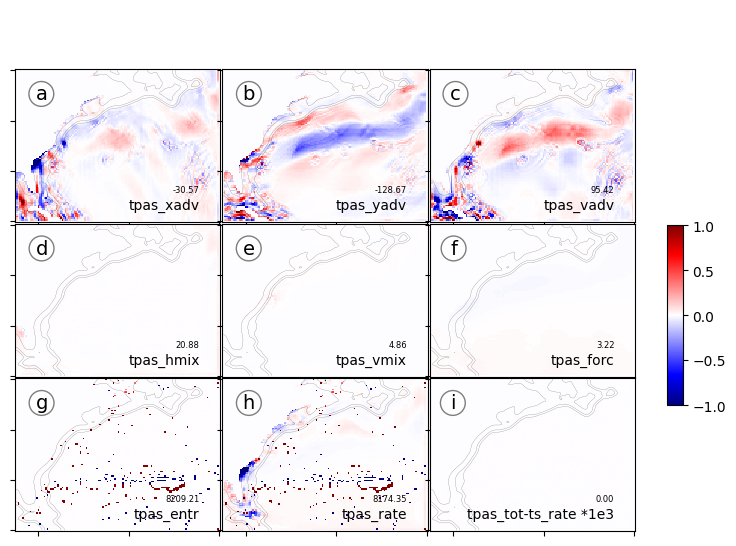

In [15]:
# Reload simul_his for MLD-specific time range (intentional reload)
simul_his = load(mysimul, time=time_his, output=False)
simul_ts = load(mysimul + '_ts', time=time_his-1, output=False)
######


print('diags_ts_' + simul_ts.simul)

######
mask = simul_ts.mask * (hbls_off if not croco_vertint else 1)

suffixes = ['rate', 'xadv', 'yadv', 'vadv', 'hmix', 'vmix', 'forc', 'entr']
ts_mld = {
    s: var(f'{tracer}_{s}_mld', simul_ts).data * mask
    for s in suffixes
}

ts_rate_mld, ts_xadv_mld, ts_yadv_mld, ts_vadv_mld, \
ts_hmix_mld, ts_vmix_mld, ts_forc_mld, ts_entr_mld = ts_mld.values()
######

# sum
ts_tot_mld = ts_xadv_mld + ts_yadv_mld + ts_vadv_mld + ts_hmix_mld + ts_vmix_mld + ts_forc_mld + ts_entr_mld

print('######################################')
print('tsrate is ', np.nansum(ts_rate_mld))
print('tstot - tsrate is ', np.nansum(ts_tot_mld - ts_rate_mld))
print('error is', np.abs(np.nansum(ts_tot_mld - ts_rate_mld)/np.nansum(ts_rate_mld)))
print('######################################')

titles = ['tpas_xadv', 'tpas_yadv', 'tpas_vadv', 'tpas_hmix', 'tpas_vmix',\
          'tpas_forc', 'tpas_entr', 'tpas_rate', 'tpas_tot-ts_rate *1e3']

coeflev = np.nanmax(np.abs(ts_rate_mld))*1e-3

panels9(simul_ts,ts_xadv_mld,\
                 ts_yadv_mld,\
                 ts_vadv_mld,\
                 ts_hmix_mld,\
                 ts_vmix_mld,\
                 ts_forc_mld,\
                 ts_entr_mld,\
                 ts_rate_mld,\
                 (ts_tot_mld-ts_rate_mld)*1e3 ,'check_tsvert_mld_' + simul_ts.simul,\
                 coeflev=coeflev, titles= titles)

###################################################################################



## Recompute the MLD integrated tracer budget terms

- Check that the 3d tracer terms vertically integrated (here just a sum) over the ML gives the same than the MLD integrated tracer budget

$$  \Sigma^N_{k^{n}_{ML}} \Delta C_{j}^{n+1} = \Delta C_{ML,j}^{n+1} $$

- Note that the vertically integrated rate will give the sum of the MLD rate and entrainment:

$$  \Sigma^N_{k^{n}_{ML}} \Delta C_{rate}^{n+1} = \Delta C_{ML,rate}^{n+1} + \Delta C_{ML,entr}^{n+1} $$


diags_ts_gulfstream_diagnostics_tracer_2026_ts
######################################
tsrate is  -120778964.31573647
tstot - tsrate is  -2.495979356353928e-05
error is 2.066567941275783e-13
######################################


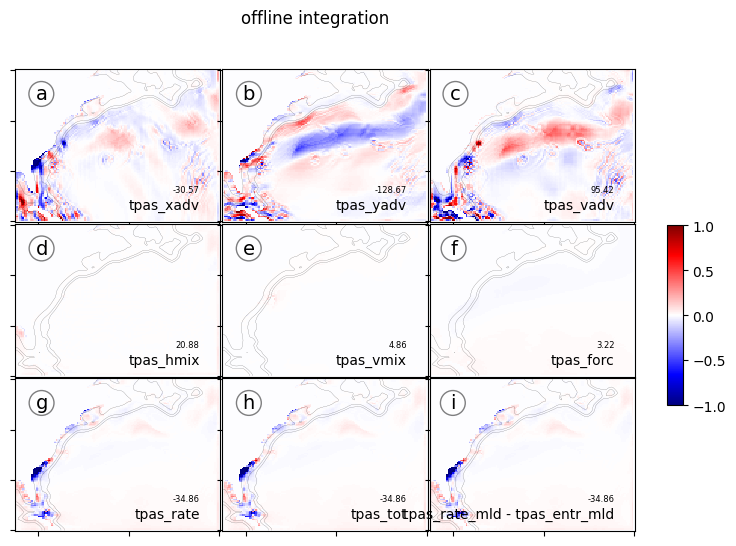

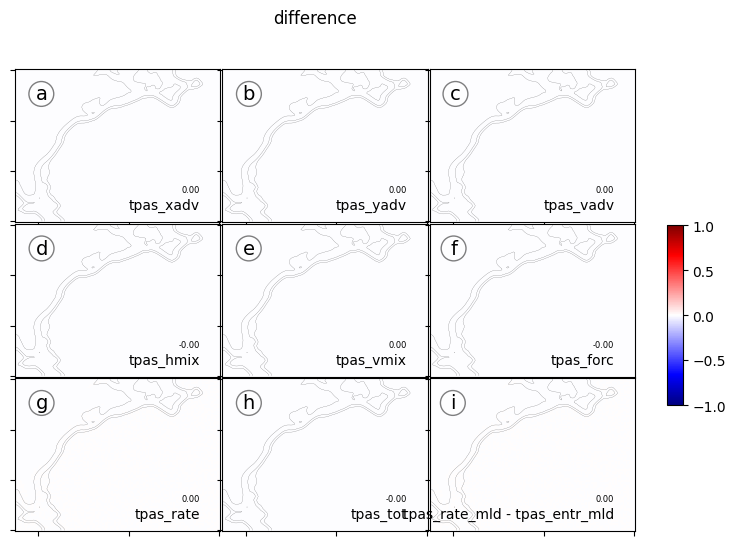

In [18]:


print('diags_ts_' + simul_ts.simul)

if croco_vertint:
    Hz_tmp = Hz_hbl_mask
else:
    Hz_tmp = Hz_hbl
    
ts_rate = vert(var(tracer+'_rate',simul_ts).data,Hz_tmp)*simul_ts.mask
ts_xadv = vert(var(tracer+'_xadv',simul_ts).data,Hz_tmp)*simul_ts.mask
ts_yadv = vert(var(tracer+'_yadv',simul_ts).data,Hz_tmp)*simul_ts.mask
ts_vadv = vert(var(tracer+'_vadv',simul_ts).data,Hz_tmp)*simul_ts.mask
ts_hmix = vert(var(tracer+'_hmix',simul_ts).data,Hz_tmp)*simul_ts.mask
ts_vmix = vert(var(tracer+'_vmix',simul_ts).data,Hz_tmp)*simul_ts.mask
ts_forc = vert(var(tracer+'_forc',simul_ts).data,Hz_tmp)*simul_ts.mask

# sum
ts_tot = ts_xadv + ts_yadv + ts_vadv + ts_hmix + ts_vmix + ts_forc

print('######################################')
print('tsrate is ', np.nansum(ts_rate))
print('tstot - tsrate is ', np.nansum(ts_tot - ts_rate))
print('error is', np.abs(np.nansum(ts_tot - ts_rate)/np.nansum(ts_rate)))
print('######################################')

titles = ['tpas_xadv', 'tpas_yadv', 'tpas_vadv', 'tpas_hmix', 'tpas_vmix',\
          'tpas_forc',  'tpas_rate', 'tpas_tot','tpas_rate_mld - tpas_entr_mld']

#coeflev = np.nanmax(np.abs(ts_rate_mld))*0.1

panels9(simul_ts,ts_xadv,\
                 ts_yadv,\
                 ts_vadv,\
                 ts_hmix,\
                 ts_vmix,\
                 ts_forc,\
                 ts_rate,\
                 ts_tot,\
                 ts_rate_mld - ts_entr_mld,'check_tsvert_mld_offline_' + simul_ts.simul,\
                 title='offline integration', coeflev=coeflev,titles= titles)

###################################################################################


panels9(simul_ts,ts_xadv-ts_xadv_mld,\
                 ts_yadv-ts_yadv_mld,\
                 ts_vadv-ts_vadv_mld,\
                 ts_hmix-ts_hmix_mld,\
                 ts_vmix-ts_vmix_mld,\
                 ts_forc-ts_forc_mld,\
                 ts_rate-ts_rate_mld+ts_entr_mld,\
                 ts_tot-ts_tot_mld+ts_entr_mld,\
                 ts_rate-ts_rate_mld+ts_entr_mld,'check_tsvert_mld_offline_diff_' + simul_ts.simul,\
                 title='difference', coeflev=coeflev, titles= titles)



## ML Tracer Budget

- Check that the ML budget terms ($\Delta C_{ML}^{n+\frac{1}{2}}$) capture the time evolution of the ML integrated tracer between time steps $n$ and $n+1$.

$$  \frac{\Sigma^N_{k^{n+1}_{ML}} H^{n+1} C^{n+1} - \Sigma^N_{k^{n}_{ML}} H^{n} C^n}{\Delta t} dx dy=  \sum_j \, \Delta C_{ML,j}^{n+\frac{1}{2}}$$

The l.h.s is computed by using two history files, the r.h.s. by using tracer budget terms averaged over the corresponding period.

The result is perfectly closed.


 
check that the following scrum times are the same: 
history:  32580
tracer budget:  32580
average:  32580
21600


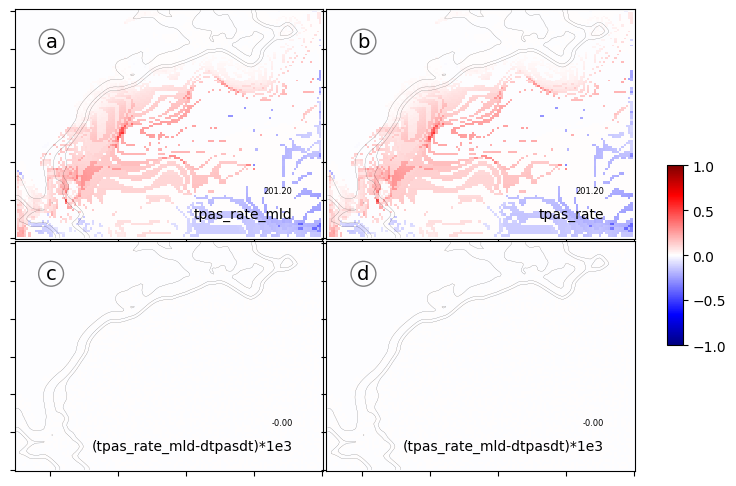

In [19]:
# check with all data
###########################################################################

simul_ts = load(mysimul + '_ts_avg', time = time_avg, output = False)
simul_avg = load(mysimul + '_avg', time = time_avg, output = False)
simul_his_0 = load(mysimul + '_his', time = time_his_0, output = False)
simul_his_1 = load(mysimul + '_his', time = time_his_1, output = False)

###########################################################################

print(' ')
print('check that the following scrum times are the same:', end=' \n') 
print('history: ',(simul_his_0.oceantime + simul_his_1.oceantime + int(simul_his_0.dt_model))//2)
print('tracer budget: ',simul_ts.oceantime )
print('average: ',simul_avg.oceantime )

print(simul_his_1.oceantime - simul_his_0.oceantime)
###########################################################################

# integrate tracer:

Hz_0 = get_Hz_hbl(simul_his_0)
Hz_1 = get_Hz_hbl(simul_his_1)

#Hz_0 = get_Hz(simul_his_0)
#Hz_1 = get_Hz(simul_his_1)

tpas0 = vert(var(tracer,simul_his_0).data,Hz_0)\
        * simul_his_0.mask / simul_his_0.pm / simul_his_0.pn
tpas1 = vert(var(tracer,simul_his_1).data,Hz_1)\
        * simul_his_1.mask / simul_his_1.pm / simul_his_1.pn

dtsdt = ( tpas1 - tpas0 ) / simul_avg.dt

#########

ts_rate_mld = var(tracer+'_rate_mld',simul_ts).data * simul_ts.mask

if not croco_vertint:
    ts_rate_mld = ts_rate/ simul_his_0.pm / simul_his_0.pn

#########

titles = ['tpas_rate_mld', 'tpas_rate', '(tpas_rate_mld-dtpasdt)*1e3','(tpas_rate_mld-dtpasdt)*1e3']

panels4(simul_avg,ts_rate_mld,\
                  dtsdt,\
                  (ts_rate_mld-dtsdt)*1e3,\
                  (ts_rate_mld-dtsdt)*1e3,\
        'diags_tsrate_' + simul_avg.simul,\
        titles= titles, coeflev=1e8)


In [20]:
'''
ts_xout_mld = var(tracer+'_xout_mld',simul_ts).data*simul_ts.mask
ts_yout_mld = var(tracer+'_yout_mld',simul_ts).data*simul_ts.mask

titles = ['tpas_xadv', 'tpas_xout', ' ', 'tpas_yadv', 'tpas_yout', ' ',\
          ' ',  ' ', ' ']

coeflev = np.nanmax(np.abs(ts_xadv))/100

panels9(simul_ts,ts_xadv_mld,\
                 ts_xout_mld,\
                 ts_vmix_mld*0.,\
                 ts_yadv_mld,\
                 ts_yout_mld,\
                 ts_forc_mld*0.,\
                 ts_entr_mld*0.,\
                 ts_rate_mld*0.,\
                 ts_tot_mld*0.,'diags_tpas02_' + simul_ts.simul, titles= titles)
'''

"\nts_xout_mld = var(tracer+'_xout_mld',simul_ts).data*simul_ts.mask\nts_yout_mld = var(tracer+'_yout_mld',simul_ts).data*simul_ts.mask\n\ntitles = ['tpas_xadv', 'tpas_xout', ' ', 'tpas_yadv', 'tpas_yout', ' ',          ' ',  ' ', ' ']\n\ncoeflev = np.nanmax(np.abs(ts_xadv))/100\n\npanels9(simul_ts,ts_xadv_mld,                 ts_xout_mld,                 ts_vmix_mld*0.,                 ts_yadv_mld,                 ts_yout_mld,                 ts_forc_mld*0.,                 ts_entr_mld*0.,                 ts_rate_mld*0.,                 ts_tot_mld*0.,'diags_tpas02_' + simul_ts.simul, titles= titles)\n"